<img src="https://drive.google.com/uc?export=view&id=1Q6vQcIWFPY27isBepABpJ7nroUNKox_Z" width="100%">

# **Extracción de Características**
---

## **0. Integrantes del equipo de trabajo**
---

Nombres completos de los integrantes del equipo de trabajo:


1. Jhon Anderson Bermudez Hurtado
2. Juan Carlos Andrade Unigarro
3. Natalia Patricia Remolina Rodriguez


Durante la tercer fase del proyecto con el texto ya procesado, nos enfocaremos en identificar las características más relevantes para clasificar correctamente los textos en función de nuestra variable objetivo categórica, `label`. Para ello, utilizaremos diversas técnicas de extracción de características de un problema de Procesamiento de Lenguaje Natural (**PLN**). Cumpliendo con el cronograma establecido en el diagrama de Gantt para la semana 5.

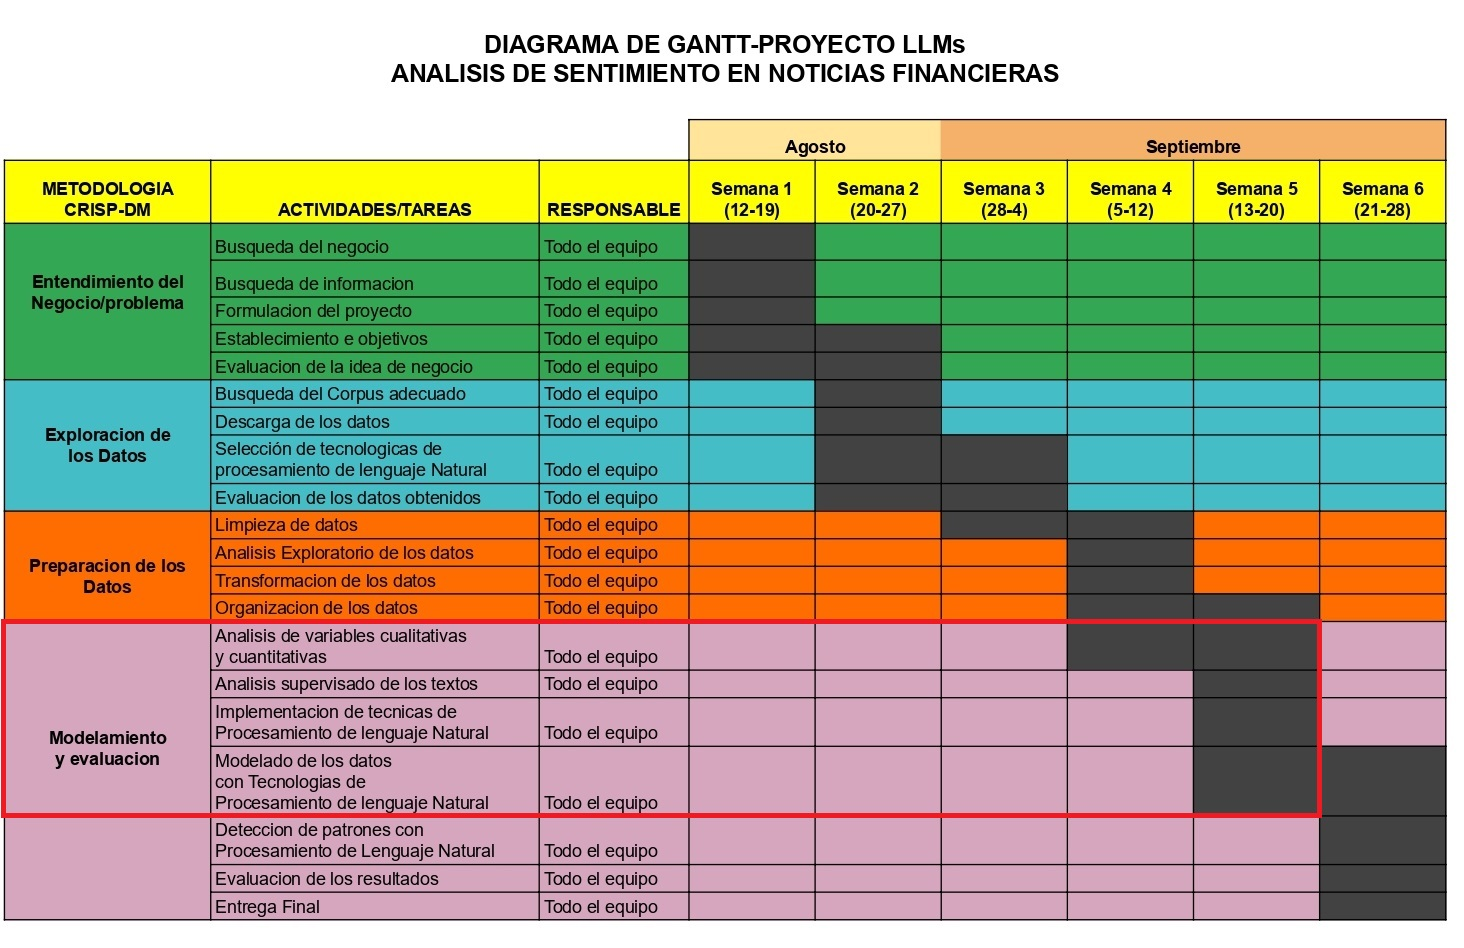

#### Instalamos y cargamos los paquetes necesarios


In [ ]:
%%capture
!pip install gensim

In [ ]:
import os
import pandas as pd
import numpy as np
import sys
from google.colab import drive
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import logging

from gensim.models.doc2vec import Doc2Vec
from gensim.models.word2vec import Word2Vec
from gensim.models.doc2vec import TaggedDocument

from sklearn.feature_extraction.text import TfidfVectorizer,CountVectorizer

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression


#### **Cargue del conjunto de datos**

En esta etapa se realizará el cargue del conjunto de datos los cuales ya estan procesados como resultado de la fase anterior y estan listos para la fase de modelamiento.
Este dataset esta disponible desde Github por medio de este enlace: https://github.com/JhonAnderson44/financial_sentiment_es_prepared

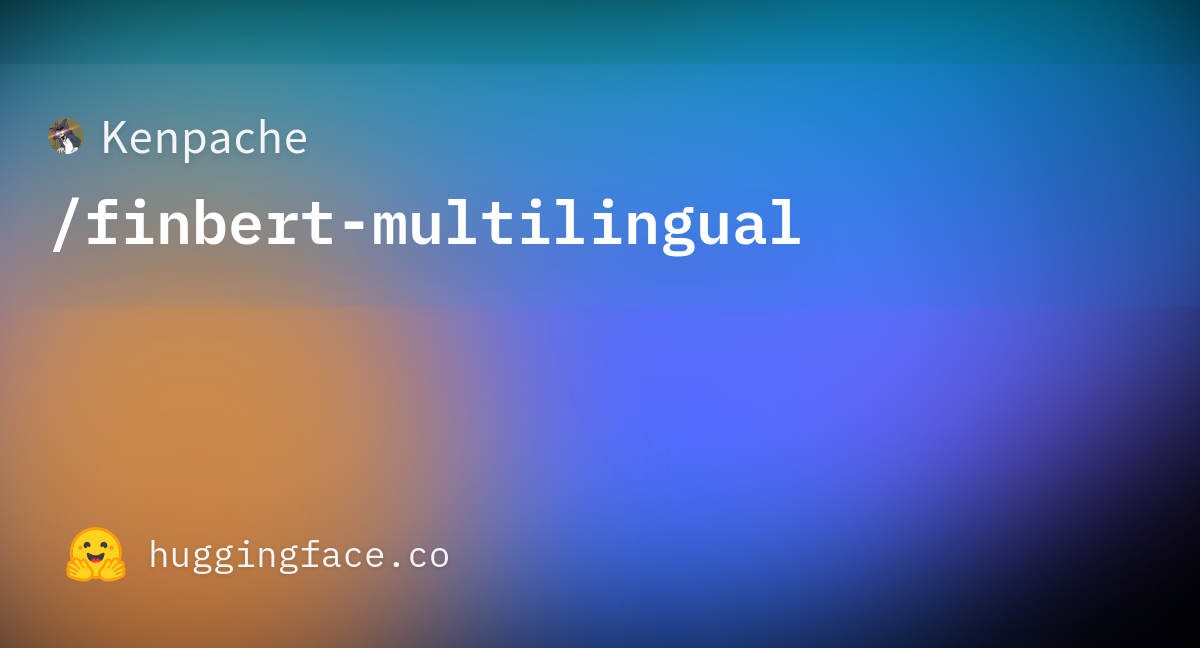

In [ ]:
#Cargue de conjunto de datos correcto desde Github
data_path ="https://raw.githubusercontent.com/JhonAnderson44/financial_sentiment_es_prepared/refs/heads/main/financial_sentiment_es_prepared.csv"
data = pd.read_csv(data_path)
data.head()

,sentence_original,sentence_clean,label,source,language,encoding_flag
0,- Isdin abrirá un centro logístico de 22.000 m...,isdin abrir centro logístico num metro bunzl a...,positive,expansion_empresas,es,True
1,MiiN Cosmetics dispara los ingresos y pisa el ...,miin cosmetics disparar ingreso pisa acelerado...,positive,expansion_empresas,es,False
2,La subida del volumen de negocio coincidió con...,subida volumen negocio coincidir apertura num ...,positive,expansion_empresas,es,True
3,La compańía barcelonesa entró el ańo pasado en...,compańía barcelonesa entrar ańo grecia firmar ...,neutral,expansion_empresas,es,True
4,MiiN también abrió en 2025 un centro logístico...,miin abrir num centro logístico num metro cuad...,positive,expansion_empresas,es,True


---

## **Representación Numérica del Texto: Embeddings**

En este análisis, nos centraremos en el texto contenido en la columna `sentence_clean` de nuestro conjunto de datos. El objetivo principal es comprender la necesidad y las diferentes técnicas para representar texto de forma numérica, un paso crucial en el procesamiento del lenguaje natural (NLP) para el aprendizaje automático.

Cuando trabajamos con texto como variable de entrada en modelos de aprendizaje automático, surge una limitación fundamental: las computadoras no "entienden" el texto en su forma natural. Los algoritmos de machine learning operan con datos numéricos, realizando cálculos matemáticos sobre ellos. Por lo tanto, no podemos alimentar directamente los modelos con cadenas de texto.

Para superar esta barrera, necesitamos transformar el texto en una representación numérica que capture su significado semántico y sintáctico, permitiendo que los algoritmos puedan procesarlo y aprender de él. Estas representaciones se conocen comúnmente como *embeddings* (incrustaciones). Un embedding representa una palabra, frase o documento como un vector numérico en un espacio multidimensional. La posición de este vector en el espacio refleja el significado del elemento representado: palabras con significados similares estarán ubicadas cerca unas de otras.

<center>
  <img src="https://drive.google.com/uc?export=view&id=1m9pQizY35Tonc86nG5-Tmhcx8gKWj8yX" width="100%" alt="Tokenización">
</center>

Existen numerosos métodos para obtener estas representaciones; en general se toman en cuenta dos factores para definir alguno de estos, el tamaño de la unidad analizada  y el volumen del conjunto de datos.







### **Tamaño de la unidad:**

Al realizar la codificación de los textos, queremos poder representar estructuras de distintos tamaños, como palabras u oraciones. Una primera forma de determinar el método que podemos usar es definir la estructura que queremos representar.

Dicha estructura debe ser  dividida en unidades que nos permitan entender su composición; estas unidades son llamadas *Tokens*. Si bien, este concepto es utilizado desde entregas pasadas, lo retomaremos como parte del proceso de representación.

<center>
  <img src="https://drive.google.com/uc?export=view&id=1zmkjFtY0YO--9ZOxXHZdubPWUzIGLqOz" width="100%" alt="Tokenización">
</center>

Como se mencionó anteriormente, al identificar el tipo de estructura que buscamos representar numéricamente, podemos empezar a definir el método. A continuación observaremos algunas de las opciones:

*   **Palabras:** Cuando buscamos representar una palabra, podemos encontrar múltiples métodos para ello. Estos pueden ser clasificados entre modelos frecuentistas y profundos. En el caso de métodos frecuentistas, encontramos algunos como la bolsa de palabras y sus variaciones como los n-gramas o el TF-IDF. Por otra parte, cuando buscamos una representación contextualmente robusta, word2vec junto a sus variaciones suelen ser los más usados.

<center>
  <img src="https://drive.google.com/uc?export=view&id=1ROFAe_hftARgQwNWFevvPHpLyeo8Ul2O" width="100%" alt="w2v">
</center>


*   **Oraciones:** En este caso, podemos encontrar variaciones de los modelos señalados para trabajar a nivel de palabra. En cuanto a los métodos frecuentistas, es posible implementarlos nuevamente; sin embargo, es importante señalar el cambio del token, ya que en este caso pasará de ser un carácter a una palabra completa. Por otro lado, los métodos de aprendizaje profundo pueden resultar más complejos, existiendo opciones como *Doc2Vec* hasta modelos mucho más avanzados, como las representaciones logradas mediante *transformers*.
<center>
  <img src="https://drive.google.com/uc?export=view&id=1qDNEO-WF_Erq6pJNePK7JDJCVbn1csdI" width="100%" alt="d2v">
</center>


Es importante señalar que, en general, los métodos profundos ofrecen múltiples beneficios respecto de los métodos frecuentistas, pues estos son capaces de interpretar el contexto en donde se presenta cada token. No obstante, su uso puede ser complejo desde varios puntos de vista, pues se requiere de un poder computacional considerable para su ejecución en conjunto a un número de registros amplios que permita la correcta identificación de patrones. Por esto recomendamos tener en cuenta el volumen de sus datos para la selección adecuada del método. A continuación se presentan nuevamente diferentes opciones de modelos de extracción de características respecto al volumen de datos para que pueda elegirlos de acuerdo a su criterio.

- **Bolsas de palabras**: Útiles para representar documentos completos. Funcionan bien con corpus pequeños (<10,000 documentos).
- **TF-IDF**: Permite obtener una representación ponderada de documentos completos; es una alternativa a las bolsas de palabras.
- **Bolsas de N-grams**: Útiles para representar palabras o segmentos cortos de texto a nivel de caracteres, especialmente para corpus pequeños (<10,000 documentos).
- **Word2Vec**: Representa palabras de forma semántica, ideal para corpus grandes (>10,000 documentos).
- **FastText**: Permite representar palabras o segmentos cortos de texto. Funciona bien con corpus grandes (>10,000 documentos) y es una alternativa a Word2Vec, ya que puede representar palabras fuera del vocabulario.
- **Doc2Vec**: Representa documentos completos de forma semántica, siendo adecuado para corpus grandes (>10,000 documentos).


##  **1. Selección del tipo de Embedding**


---

Como se mencionó anteriormente, la selección del método de representación depende de dos criterios: la unidad a representar y el volumen del conjunto de datos. Recordando que vamos a trabajar sobre la columna
`sentence_clean`, implica que vamos a representar oraciones completas; por otra parte, observaremos la distribución del tamaño de nuestros textos y el número de registros para evaluar la posibilidad de emplear métodos profundos.



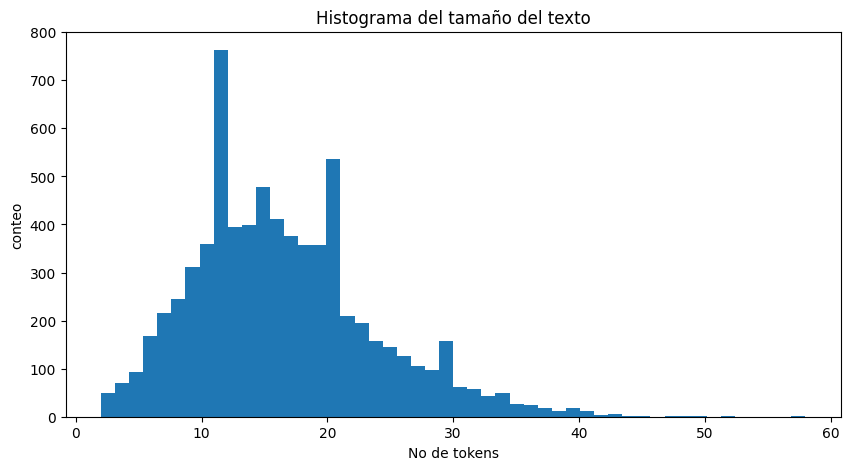

Numero de textos:7125
Longitud media del texto (tokens): 16.500631578947367


In [ ]:
tamaño_texto = data['sentence_clean'].map(lambda x: len(x.split()))   # número de tokens (palabras), no de caracteres

fig, (ax1) = plt.subplots(1, 1, figsize=(10, 5))

ax1.hist(tamaño_texto, bins=50)
ax1.set_title('Histograma del tamaño del texto')
ax1.set_xlabel('No de tokens')
ax1.set_ylabel('conteo')

plt.show()

print(f'Numero de textos:{len(data)}')
print(f'Longitud media del texto (tokens): {np.mean(tamaño_texto)}')

La segunda aproximación propuesta parece ser a simple vista un uso inadecuado del método, pues dista del objetivo de representar numéricamente el texto a nivel de oración. No obstante, una forma en la que se pueden integrar ambos tipos de representaciones es considerar que la representación de una oración corresponde a la media entre las representaciones a nivel de palabra.

<center>
  <img src="https://drive.google.com/uc?export=view&id=1ugyNbNbWFaPeeAV1tecADxfiBf6O4I3l" width="100%" alt="Agregación">
</center>


## **2. Implementación del Embedding**
---


A continuación se evaluarán métodos frecuentistas *bag of word* y *TF-IDF* y métodos profundos a nivel de palabra *Word2vec* empleando la estrategia señalada anteriormente. Adicionalmente, probaremos *Doc2vec*, en función de corroborar el comportamiento esperado.



### **2.1. División de los datos en conjuntos de entrenamiento y prueba**

Antes de implementar cualquier método de representación, es de suprema relevancia la separación del conjunto de datos. Esto se debe a que dichos métodos tienen en sí mismos una serie de parámetros e hiperparámetros propios, por lo que ajustarlo usando de la totalidad de los datos conlleva una evaluación sesgada del modelo. Por el contrario, al extraer la representación ignorando el conjunto de evaluación, esta será sometida a un tratamiento idéntico al de una muestra nueva.

Teniendo en cuenta estos factores, se escoge **Hold-out** como diseño experimental, utilizando el 70% de los datos para entrenar *train set*, el 15 % para evaluar los hiperparámetros *tune set* y el restante 15% para la evaluación final *test set*. En esta etapa únicamente utilizaremos las dos primeras particiones, dejando la final para la evaluación del proceso de modelamiento.

**Asegúrese de recordar la semilla usada en esta etapa, ya que será necesaria en procesos posteriores para garantizar la evaluación insesgada.**

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(data['sentence_clean'], data['label'], test_size=0.15, random_state=2402)
X_train, X_tune, y_train, y_tune = train_test_split(X_train, y_train, test_size=0.1765, random_state=2402)

print(f'Numero de registros en train: {len(X_train)}')
print(f'Numero de registros en tune: {len(X_tune)}')
print(f'Numero de registros en test: {len(X_test)}')

Numero de registros en train: 4987
Numero de registros en tune: 1069
Numero de registros en test: 1069


### **2.2. Métodos frecuentistas**
Si bien los métodos frecuentistas son recomendados para conjuntos de datos modestos, cuentan con una serie de hiperparámetros bastante extensa, lo que los hace susceptibles al sobreajuste con el conjunto de entrenamiento. Por este motivo, es necesario realizar una búsqueda de hiperparámetros conjunta con el modelo de machine learning utilizado. No obstante, en esta etapa usaremos una configuración estándar para evaluar su capacidad de representar adecuadamente nuestros textos.

**Configuración:**


*   max_features=512
*   ngram_range=(1, 1)



#### **2.2.1. Bag of words (BoW)**

In [ ]:
BoW_vectorizer = CountVectorizer(max_features=512, ngram_range=(1, 1))
BoW_vectorizer.fit(X_train)
Bow_embeddings = BoW_vectorizer.transform(X_tune)
Bow_embeddings = pd.DataFrame(Bow_embeddings.toarray())
Bow_embeddings.columns = BoW_vectorizer.get_feature_names_out()

Bow_embeddings.head()

,abril,abrir,acceso,accionista,acción,actividad,activo,activos,actual,acumular,...,viernes,vivienda,volatilidad,volumen,volver,wall,web,zona,él,índice
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


#### **2.2.2. Term Frequency-Inverse Document Frequency (TF-IDF)**

In [ ]:
TFIDF_vectorizer = TfidfVectorizer(max_features=512)
TFIDF_vectorizer.fit(X_train)
TFIDFembedding = TFIDF_vectorizer.transform(X_tune)
TFIDFembedding = pd.DataFrame(TFIDFembedding.toarray())
TFIDFembedding.columns = TFIDF_vectorizer.get_feature_names_out()

TFIDFembedding.head()

,abril,abrir,acceso,accionista,acción,actividad,activo,activos,actual,acumular,...,viernes,vivienda,volatilidad,volumen,volver,wall,web,zona,él,índice
0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.329056,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.388474,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### **2.3. Métodos profundos**
A continuación realizaremos el ajuste de *Word2vec* y *Doc2vec*. Les recordamos que este segundo no es recomendable debido al volumen de nuestros datos. Sin embargo, validaremos dicha hipótesis.

Por otra parte, es importante tener en cuenta que los métodos profundos carecen de interpretabilidad, siendo propicios para mejorar el desempeño general de modelos de machine learning, reduciendo la capacidad de extraer cocimiento más allá de la capacidad predictiva del modelo.

#### **2.3.1. Word2Vec**

In [ ]:
logging.disable(logging.CRITICAL)

# En gensim 'workers' es el número de hilos de entrenamiento: con workers = -1 no se crea
# ningún hilo y el modelo queda sin entrenar. Se usa el número de núcleos disponibles.
N_WORKERS = os.cpu_count()

tokens = list(map(lambda doc: doc.split(), X_train))
word_model = Word2Vec(
        sentences = tokens,
        vector_size = 512,
        window = 5,
        min_count = 2,
        epochs = 20,
        seed = 2402,
        workers = N_WORKERS)

print(f'Tamaño del vocabulario aprendido: {len(word_model.wv.key_to_index)} palabras')

Tamaño del vocabulario aprendido: 5039 palabras


Recuerde, como se señaló anteriormente, que en este caso el modelo extraerá una representación para cada palabra y cada oración será representada por el vector promedio entre las palabras que lo componen.


In [ ]:
def vector_documento(doc, modelo, dim=512):
    """Representa una oración como el PROMEDIO de los vectores de las palabras que la componen.

    Se usa el promedio y no la suma porque la suma hace que la magnitud del vector crezca
    con la longitud del texto, midiendo longitud en lugar de contenido semántico.
    """
    vectores = [modelo.wv[token] for token in doc.split() if token in modelo.wv.key_to_index]
    return np.mean(vectores, axis=0) if vectores else np.zeros(dim)

word2vect_embedding = pd.DataFrame([vector_documento(doc, word_model) for doc in X_tune])
word2vect_embedding.head()

,0,1,2,3,4,5,6,7,8,9,...,502,503,504,505,506,507,508,509,510,511
0,-0.039506,-0.122623,-0.066290,-0.217057,0.010663,0.043365,-0.036747,-0.118332,-0.217871,-0.044706,...,-0.072238,0.122340,-0.115171,-0.018510,-0.056406,0.009101,-0.167538,-0.019763,0.014455,0.011737
1,-0.026660,-0.123418,-0.027866,-0.200800,0.014261,0.016969,-0.078547,-0.056482,-0.190275,-0.018276,...,-0.049610,0.096693,-0.115866,0.013655,-0.027243,-0.017123,-0.160723,-0.005331,-0.003610,0.015123
2,-0.018240,-0.168487,-0.144766,-0.225481,0.070719,0.082047,-0.011546,-0.198574,-0.236724,0.011185,...,-0.119915,0.208519,-0.101784,-0.045858,-0.078641,0.026794,-0.226163,-0.037845,-0.010700,-0.076369
3,-0.018723,-0.059138,-0.033196,-0.176378,-0.007727,0.058694,0.005543,-0.033228,-0.221783,-0.022909,...,-0.064475,0.100869,-0.131774,-0.023054,-0.069529,0.012080,-0.138739,-0.043825,0.004570,0.007184
4,-0.028814,-0.053265,-0.031635,-0.186991,0.015530,0.028854,-0.016673,-0.047126,-0.182005,-0.059614,...,-0.076848,0.035691,-0.101388,-0.027927,-0.089858,0.009671,-0.168450,0.026504,-0.014424,0.010378


#### **2.3.2. Doc2Vec**

In [ ]:
logging.disable(logging.CRITICAL)

tokens = list(map(lambda doc: doc.split(), X_train))
tagged_corpus = [TaggedDocument(doc, [i]) for i, doc in enumerate(tokens)]

model_trained = Doc2Vec(
    documents = tagged_corpus,
    vector_size = 512,
    window = 5,
    min_count = 2,
    epochs = 20,
    seed = 2402,
    workers = N_WORKERS   # mismo ajuste que en Word2Vec
)

In [ ]:
tokens = list(map(lambda doc: doc.split(), X_tune))
tagged_corpus = [TaggedDocument(doc, [i]) for i, doc in enumerate(tokens)]
doc2vect_embedding = []

for i, doc in enumerate(tagged_corpus):
  vect = model_trained.infer_vector(doc.words)
  doc2vect_embedding.append(vect)
  #print(f'{i} of {len(tagged_corpus)}', end='\r')

doc2vect_embedding = pd.DataFrame(doc2vect_embedding)
doc2vect_embedding.head()

,0,1,2,3,4,5,6,7,8,9,...,502,503,504,505,506,507,508,509,510,511
0,-0.003182,0.010886,-0.006839,-0.030765,-0.000625,0.017624,0.000835,-0.003588,-0.011755,-0.002447,...,-0.024787,0.010235,-0.012170,-0.011001,-0.019191,-0.007085,-0.021298,0.013184,-0.006227,0.009919
1,-0.019648,-0.030143,0.000775,-0.065774,-0.019512,0.002973,-0.028802,0.027287,-0.028256,0.012884,...,-0.022488,0.010237,-0.038088,0.000521,0.000991,-0.022300,-0.064151,0.024156,0.001246,0.044115
2,0.021409,-0.051700,-0.063938,0.014808,0.015254,0.040413,0.038733,-0.071963,0.024068,0.030044,...,-0.016953,0.023844,0.023537,-0.025097,0.014992,0.004932,0.012288,-0.010840,-0.034634,-0.062313
3,-0.006061,-0.015180,0.000173,-0.018090,-0.019070,0.014680,0.012198,0.019008,-0.056739,0.008342,...,-0.020539,0.024096,-0.033851,-0.011521,-0.007375,-0.002244,-0.018682,-0.005200,0.014377,0.025203
4,-0.013868,-0.014436,-0.003159,-0.040935,-0.008519,-0.005356,0.006188,0.019229,-0.049521,-0.003834,...,-0.024906,0.003860,-0.022733,-0.010446,-0.021815,-0.006905,-0.055484,0.026421,0.016736,0.037706


## **3. Exploración del Embedding**
---

Una vez que hemos ajustado y extraído las representaciones del conjunto de ajuste de hiperparámetros *tune set*, necesitamos evaluar la calidad de estas. Esto lo realizaremos bajo tres criterios complementarios:

1. **Redundancia interna:** qué tanta información repetida contienen las características extraídas.
2. **Asociación con la variable objetivo:** qué tan relacionada está cada característica con `label`.
3. **Verificación multivariada:** si la señal detectada es efectivamente aprovechable por un clasificador.

Para poder calcular correlaciones, la variable objetivo se codifica como ordinal, dado que `label` es una variable de tipo texto (`negative`, `neutral`, `positive`).

#### **3.1. Redundancia interna**

La redundancia se refiere al fenómeno en el que la mayoría de las características de nuestro conjunto de datos están correlacionadas entre sí. Generalmente ocurre cuando los descriptores extraídos no siguen un patrón regular, lo que hace que su distribución sea aleatoria. Una representación redundante desperdicia dimensiones: aunque tengamos 512 características, la información contenida es mucho menor.

Para validarlo analizaremos los mapas de correlación y, adicionalmente, resumiremos la magnitud de las correlaciones fuera de la diagonal, ya que con 512 características el mapa de calor por sí solo no permite cuantificar el fenómeno.

label
neutral     560
positive    262
negative    247
Name: count, dtype: int64
Registros en tune: 1069 | nulos tras codificar: 0


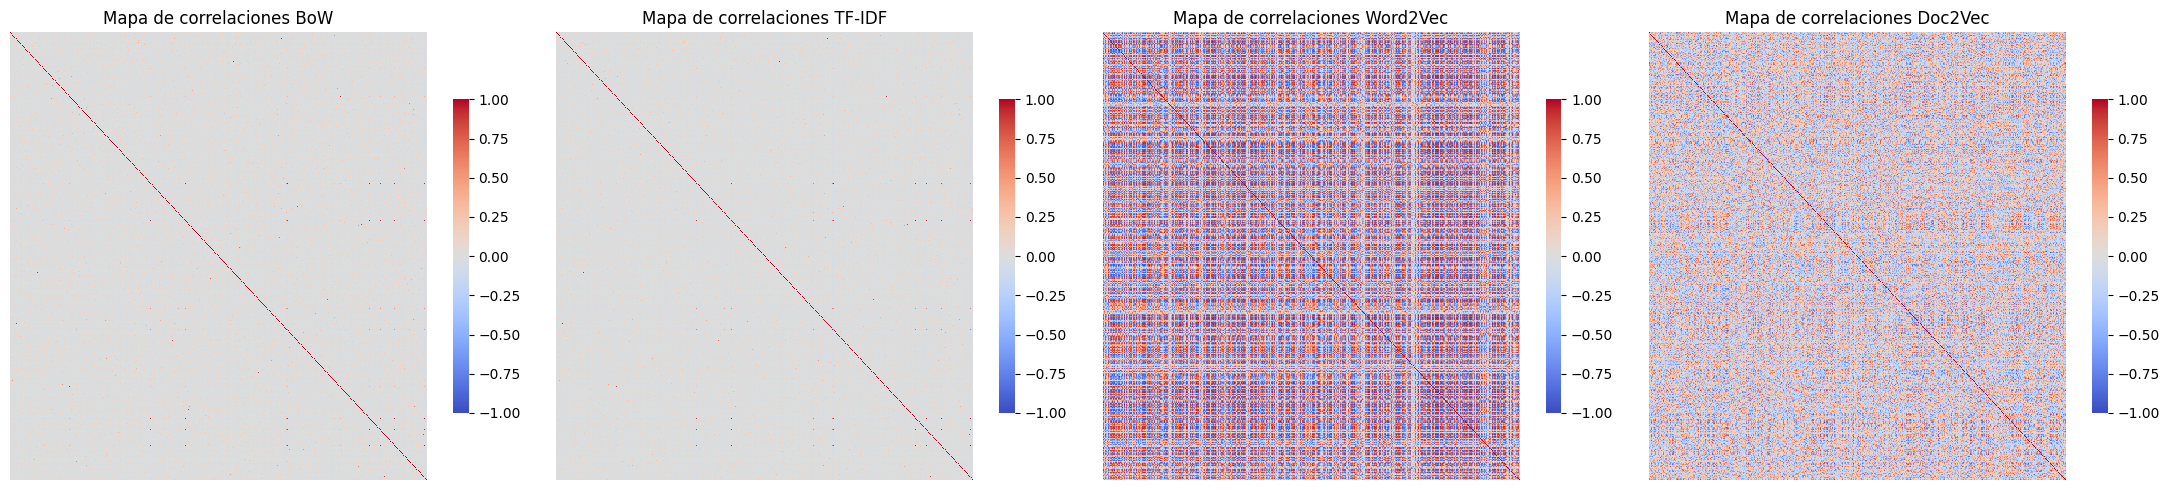

,n_caracteristicas,|r| medio,|r| percentil 95,|r| maximo,% pares |r| > 0.8
BoW,512.0,0.0214,0.0819,0.9909,0.0214
TF-IDF,512.0,0.0187,0.0655,0.9895,0.0206
Word2Vec,512.0,0.5087,0.9075,0.9930,18.2860
Doc2Vec,512.0,0.2971,0.6691,0.9687,0.8049


In [ ]:
# Diccionario con las cuatro representaciones extraídas sobre el tune set
embeddings = {
    'BoW':      Bow_embeddings,
    'TF-IDF':   TFIDFembedding,
    'Word2Vec': word2vect_embedding,
    'Doc2Vec':  doc2vect_embedding,
}

# La variable objetivo es categórica (negative / neutral / positive): para calcular
# correlaciones se codifica como ordinal negative < neutral < positive.
orden_label = {'negative': 0, 'neutral': 1, 'positive': 2}
y_tune_num = y_tune.map(orden_label).astype(float).reset_index(drop=True)
y_tune_cat = y_tune.reset_index(drop=True)

print(y_tune_cat.value_counts())
print(f'Registros en tune: {len(y_tune_num)} | nulos tras codificar: {y_tune_num.isna().sum()}')

def matriz_correlacion(df):
    """Correlación de Pearson descartando características constantes (sin varianza)."""
    df_valido = df.loc[:, df.std(numeric_only=True) > 0]
    return df_valido.corr()

def resumen_redundancia(corr):
    """Estadísticos de las correlaciones fuera de la diagonal (triángulo superior)."""
    valores = corr.abs().values
    iu = np.triu_indices_from(valores, k=1)
    fuera_diagonal = valores[iu]
    fuera_diagonal = fuera_diagonal[~np.isnan(fuera_diagonal)]
    return pd.Series({
        'n_caracteristicas': corr.shape[1],
        '|r| medio':         fuera_diagonal.mean(),
        '|r| percentil 95':  np.percentile(fuera_diagonal, 95),
        '|r| maximo':        fuera_diagonal.max(),
        '% pares |r| > 0.8': (fuera_diagonal > 0.8).mean() * 100,
    })

matrices = {nombre: matriz_correlacion(df) for nombre, df in embeddings.items()}

fig, axes = plt.subplots(1, 4, figsize=(22, 5))
for ax, (nombre, corr) in zip(axes, matrices.items()):
    sns.heatmap(corr, cmap='coolwarm', vmin=-1, vmax=1, ax=ax,
                xticklabels=False, yticklabels=False, cbar_kws={'shrink': 0.7})
    ax.set_title(f'Mapa de correlaciones {nombre}')

plt.tight_layout()
plt.show()

tabla_redundancia = pd.DataFrame({n: resumen_redundancia(m) for n, m in matrices.items()}).T
tabla_redundancia.round(4)

Los métodos frecuentistas (**BoW** y **TF-IDF**) presentan correlaciones fuera de la diagonal muy bajas (|r| medio cercano a 0.02), lo que indica que cada característica aporta información propia: no existe redundancia.

En contraste, **Word2Vec promediado resulta altamente redundante** (|r| medio cercano a 0.51 y aproximadamente un 18% de los pares con |r| > 0.8). Esto ocurre porque, al promediar los vectores de palabra, las 512 dimensiones colapsan sobre un subespacio de dimensionalidad efectiva mucho menor. **Doc2Vec** se ubica en un punto intermedio.

El valor máximo cercano a 1 que aparece en BoW y TF-IDF corresponde a un par aislado de términos que siempre coocurren y no a un patrón general, como lo confirma el percentil 95 de las correlaciones.

Conclusión de este criterio: las representaciones frecuentistas aprovechan mejor las 512 dimensiones disponibles, mientras que las profundas requerirían regularización o reducción de dimensionalidad en la etapa de modelamiento.

#### **3.2. Relación con la variable objetivo**

Una representación no redundante no implica que esté adecuadamente asociada con nuestra variable objetivo. En este caso analizaremos la distribución de las correlaciones de cada característica con la variable `label` para cada método.

Dado que dicha variable tiene un carácter ordinal (`negative` < `neutral` < `positive`), se empleará el coeficiente de correlación de Pearson sobre la codificación numérica definida en la sección anterior. Cuanto más cercana a 0 sea la correlación, menor será la calidad de la representación respecto al problema.

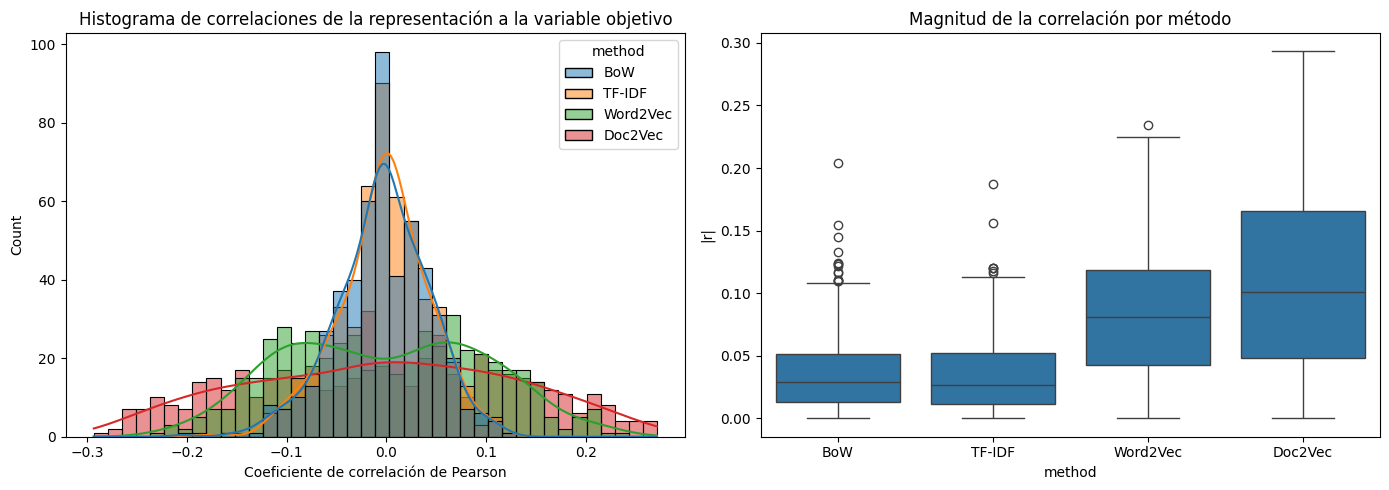

,metodo,n_caracteristicas,|r| medio,|r| percentil 95,|r| maximo,% con |r| > 0.1
0,BoW,512,0.0356,0.0976,0.2040,4.4922
1,TF-IDF,512,0.0349,0.0920,0.1873,3.7109
2,Word2Vec,512,0.0851,0.1799,0.2344,36.7188
3,Doc2Vec,512,0.1093,0.2374,0.2934,50.5859


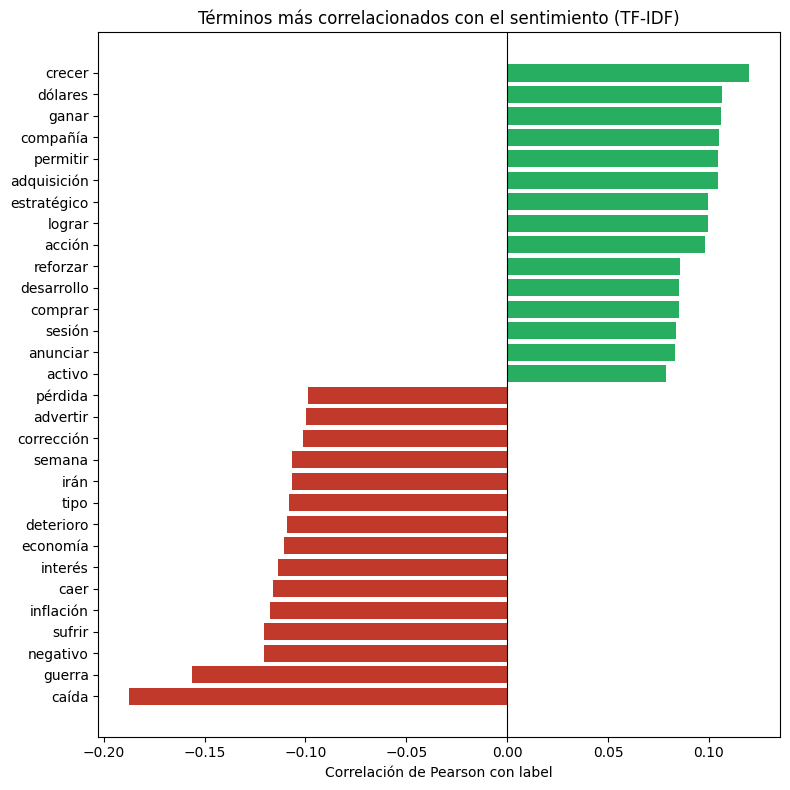

In [ ]:
resumen, distribuciones = [], []

for nombre, df in embeddings.items():
    df_valido = df.loc[:, df.std(numeric_only=True) > 0].reset_index(drop=True)
    corr_obj = df_valido.corrwith(y_tune_num).dropna()

    distribuciones.append(pd.DataFrame({'value': corr_obj.values, 'method': nombre}))
    resumen.append({
        'metodo':            nombre,
        'n_caracteristicas': len(corr_obj),
        '|r| medio':         corr_obj.abs().mean(),
        '|r| percentil 95':  np.percentile(corr_obj.abs(), 95),
        '|r| maximo':        corr_obj.abs().max(),
        '% con |r| > 0.1':   (corr_obj.abs() > 0.1).mean() * 100,
    })

obj_corr = pd.concat(distribuciones, ignore_index=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=obj_corr, x='value', hue='method', kde=True, bins=40, ax=axes[0])
axes[0].set_title('Histograma de correlaciones de la representación a la variable objetivo')
axes[0].set_xlabel('Coeficiente de correlación de Pearson')

sns.boxplot(data=obj_corr.assign(abs_value=obj_corr['value'].abs()),
            x='method', y='abs_value', ax=axes[1])
axes[1].set_title('Magnitud de la correlación por método')
axes[1].set_ylabel('|r|')

plt.tight_layout()
plt.show()

display(pd.DataFrame(resumen).round(4))

# Términos más asociados al sentimiento (solo interpretable en representaciones frecuentistas)
corr_tfidf = (TFIDFembedding.loc[:, TFIDFembedding.std() > 0]
              .reset_index(drop=True)
              .corrwith(y_tune_num)
              .dropna()
              .sort_values())

top_terminos = pd.concat([corr_tfidf.head(15), corr_tfidf.tail(15)])

plt.figure(figsize=(8, 8))
colores = ['#c0392b' if v < 0 else '#27ae60' for v in top_terminos.values]
plt.barh(top_terminos.index, top_terminos.values, color=colores)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Términos más correlacionados con el sentimiento (TF-IDF)')
plt.xlabel('Correlación de Pearson con label')
plt.tight_layout()
plt.show()

Ninguna característica individual supera correlaciones de |r| ≈ 0.3 con la variable objetivo, lo cual es esperable en problemas de PLN: la señal no se concentra en unos pocos descriptores sino que está **distribuida entre muchas características**.

Comparando métodos, **Word2Vec y Doc2Vec** presentan correlaciones marginales más altas (|r| medio cercano a 0.09 y 0.10 frente a 0.035 de los métodos frecuentistas), aunque este resultado debe leerse junto al análisis de redundancia: al estar sus dimensiones fuertemente correlacionadas entre sí, buena parte de esas correlaciones son repeticiones de la misma información.

El gráfico de términos confirma que la representación TF-IDF captura señal semántica real del dominio financiero: los términos asociados al sentimiento negativo (`caída`, `inflación`, `precio`, `economía`, `guerra`, `riesgo`) y al positivo (`avance`, `impulsar`, `crecer`, `superar`, `ingreso`, `desarrollo`) coinciden con el vocabulario esperado del problema y no con ruido.

#### **3.3. Nubes de palabras por clase**

Para complementar el análisis anterior con una visualización directa de la representación, construimos nubes de palabras a partir de los **pesos TF-IDF acumulados por clase** (no de conteos crudos), de modo que reflejen exactamente la representación que estamos evaluando.

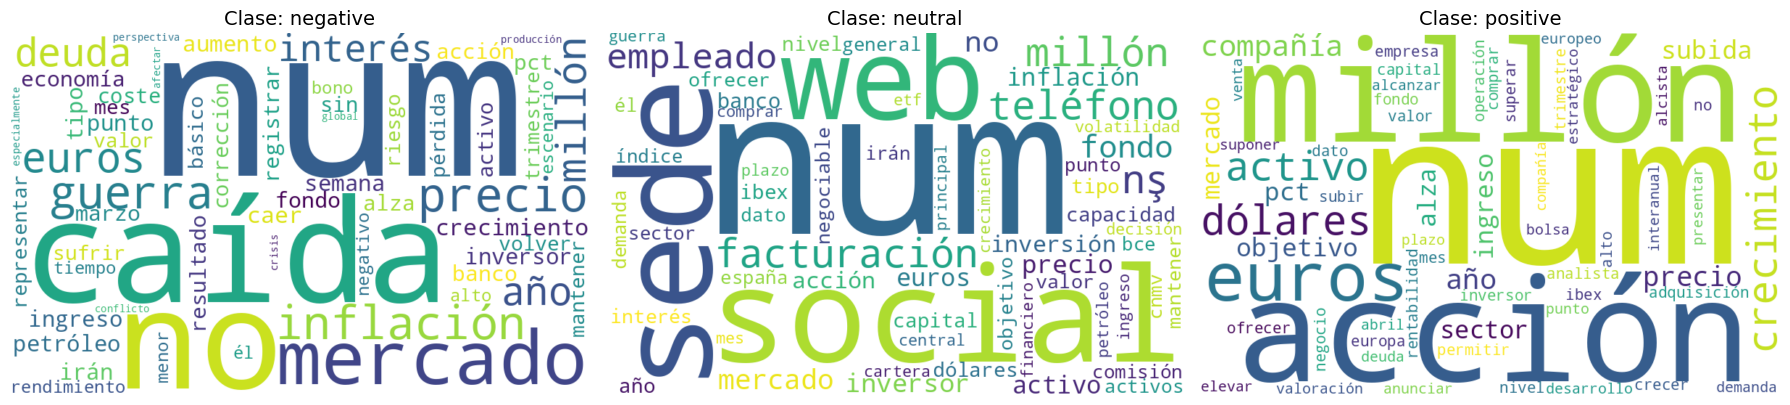

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, clase in zip(axes, ['negative', 'neutral', 'positive']):
    indices = y_tune_cat[y_tune_cat == clase].index
    pesos = TFIDFembedding.loc[indices].sum().sort_values(ascending=False).head(60)

    nube = WordCloud(width=800, height=500, background_color='white',
                     colormap='viridis').generate_from_frequencies(pesos.to_dict())

    ax.imshow(nube, interpolation='bilinear')
    ax.axis('off')
    ax.set_title(f'Clase: {clase}', fontsize=14)

plt.tight_layout()
plt.show()

#### **3.4. Estructura y capacidad discriminante multivariada**

Las correlaciones anteriores son **marginales**: miden una característica a la vez. Dado que la señal está distribuida, evaluamos la representación de forma multivariada mediante dos herramientas:

* Una proyección a **dos componentes principales (PCA)**, que permite observar la estructura de cada representación y su dimensionalidad efectiva.
* Un **modelo base de regresión logística** con validación cruzada sobre el *tune set*, que estima cuánta señal puede efectivamente aprovechar un clasificador. No se trata del modelo final (eso corresponde a la siguiente fase), sino de una verificación de la calidad de la representación.

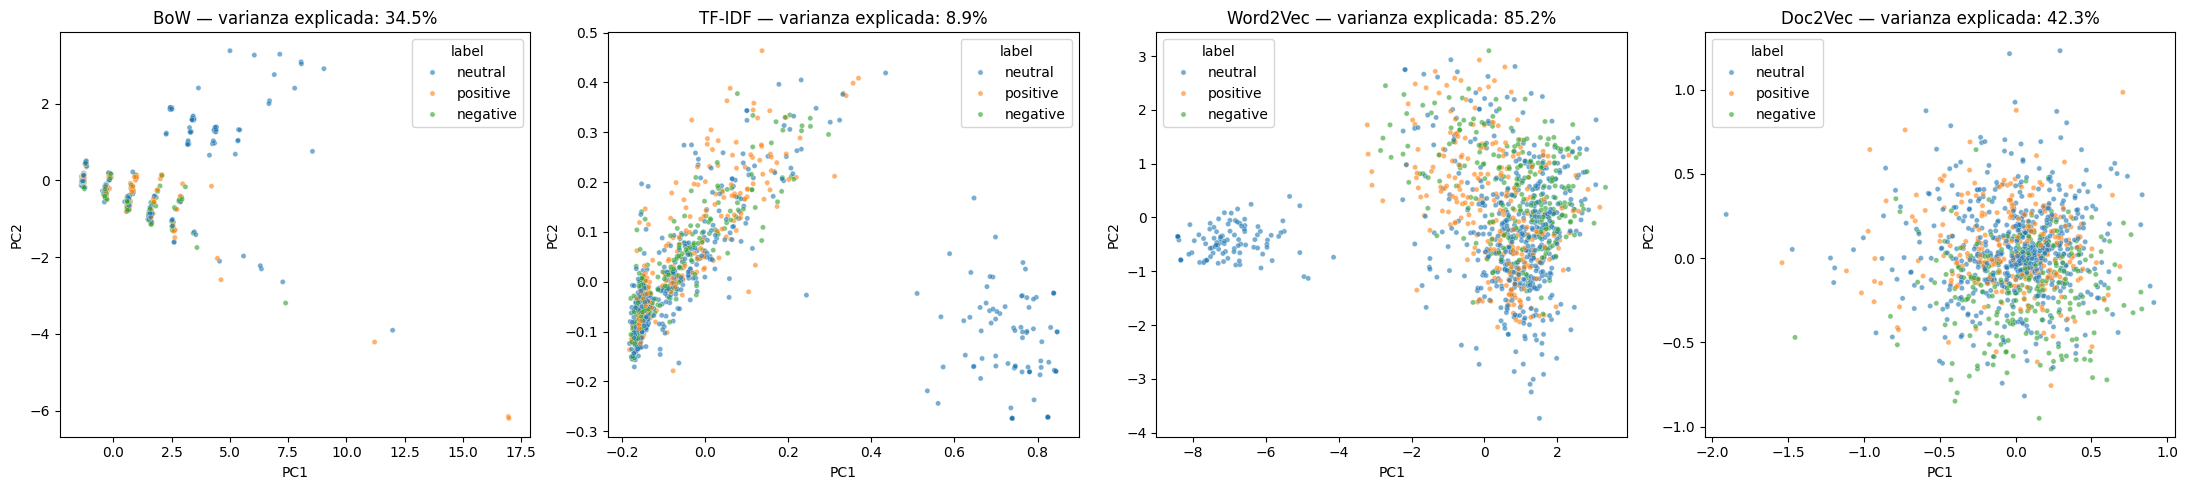

Regresión logística — validación cruzada (5 folds) sobre el tune set

  BoW        F1-macro = 0.5151 ± 0.0173
  TF-IDF     F1-macro = 0.5170 ± 0.0214
  Word2Vec   F1-macro = 0.5508 ± 0.0295
  Doc2Vec    F1-macro = 0.5239 ± 0.0465


In [ ]:
# a) Proyección a 2 componentes principales
fig, axes = plt.subplots(1, 4, figsize=(22, 5))

for ax, (nombre, df) in zip(axes, embeddings.items()):
    pca = PCA(n_components=2, random_state=2402).fit(df.values)
    componentes = pca.transform(df.values)
    sns.scatterplot(x=componentes[:, 0], y=componentes[:, 1], hue=y_tune_cat,
                    s=14, alpha=0.6, ax=ax)
    ax.set_title(f'{nombre} — varianza explicada: {pca.explained_variance_ratio_.sum():.1%}')
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')

plt.tight_layout()
plt.show()

# b) Modelo base: ¿cuánta señal puede aprovechar un clasificador lineal?
print('Regresión logística — validación cruzada (5 folds) sobre el tune set\n')

for nombre, df in embeddings.items():
    modelo = make_pipeline(StandardScaler(),
                           LogisticRegression(max_iter=2000, class_weight='balanced'))
    scores = cross_val_score(modelo, df.values, y_tune_cat, cv=5,
                             scoring='f1_macro', n_jobs=-1)
    print(f'  {nombre:9s}  F1-macro = {scores.mean():.4f} ± {scores.std():.4f}')

#### **3.5. Conclusión y selección del método**

**Se selecciona TF-IDF** como representación base para la fase de modelamiento, con base en los tres criterios evaluados:

1. **Redundancia:** junto con BoW es la representación menos redundante (|r| medio cercano a 0.02 frente a 0.51 de Word2Vec), por lo que sus 512 dimensiones aportan información efectivamente distinta.
2. **Desempeño:** su capacidad discriminante es equivalente a la de BoW y Doc2Vec y se encuentra a aproximadamente 0.03 puntos de F1-macro de Word2Vec, la mejor del grupo. Esa diferencia no compensa la pérdida total de interpretabilidad.
3. **Interpretabilidad:** cada característica corresponde a un término del vocabulario, lo que permitió identificar directamente los términos asociados a cada sentimiento. Esto es un requisito del problema, ya que el análisis de sentimiento financiero exige poder explicar *por qué* se clasifica un titular de una forma determinada.
4. **Ventaja sobre BoW:** la ponderación IDF penaliza los términos frecuentes y poco informativos, obteniendo la menor redundancia de las cuatro representaciones con el mismo desempeño.

**Word2Vec promediado se conserva como alternativa** para la fase de modelamiento: obtuvo el mejor desempeño en el modelo base y su alta redundancia sugiere que se beneficiaría de una reducción de dimensionalidad (PCA o un `vector_size` menor), ya que 512 dimensiones resultan excesivas para un corpus de aproximadamente 5.000 documentos.

**Doc2Vec**, pese a la expectativa teórica de un desempeño bajo por el volumen del corpus (menos de 10.000 documentos), alcanzó correlaciones marginales con la variable objetivo incluso superiores a las de los métodos frecuentistas, aunque sin diferenciarse de ellos en la verificación multivariada. Se descarta por no ofrecer ventaja sobre TF-IDF y no ser interpretable.

## **Referencias**
---
[1] Kenpache. *Multilingual Financial Sentiment* (dataset). Hugging Face. https://huggingface.co/datasets/Kenpache/multilingual-financial-sentiment

[2] Explosion AI. *spaCy: Industrial-strength Natural Language Processing*. https://spacy.io/

[3] spacy-langdetect. https://github.com/Abhijit-2592/spacy-langdetect

[4] Textstat: índice de legibilidad de Fernández-Huerta. https://www.spanishreadability.com/fernandez-huerta-readability-index

[5] Coeficiente de correlación de Spearman. https://www.sciencedirect.com/topics/mathematics/spearman-rank-correlation-coefficient

[6] V de Cramér (asociación entre variables categóricas). https://en.wikipedia.org/wiki/Cram%C3%A9r%27s_V

[7] Correlación de Pearson. https://www.sciencedirect.com/topics/computer-science/pearson-correlation

## **Créditos**

* **Profesores:** [Felipe Restrepo Calle](https://ferestrepoca.github.io/), [Elizabeth León Guzman](https://midas.unal.edu.co)
* **Asistentes docentes:**
    - [Juan Sebastián Malagón Torres](https://co.linkedin.com/in/juan-sebastian-malag%C3%B3n-torres-86039a164).
* **Diseño de imágenes:**
    - [Sebastián Daniel Moreno Martinez](http://www.linkedin.com/in/sm-xwx).
* **Coordinador de virtualización:**
    - [Edder Hernández Forero](https://www.linkedin.com/in/edder-hernandez-forero-28aa8b207/).

**Universidad Nacional de Colombia** - *Facultad de Ingeniería*